In [ ]:
# import required library
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

# 1. Visualization theme

In [ ]:
# Define a consistent color palette for visualizations
PRIMARY = "#4C72B0"
SECONDARY = "#DD8452"
DANGER = "#C44E52"
SUCCESS = "#55A868"
NEUTRAL = "#8172B3"

# Apply Seaborn's whitegrid style for clean and readable visualizations
sns.set_theme(style="whitegrid")

# Set the default figure dimensions (width = 12 inches, height = 6 inches)
plt.rcParams["figure.figsize"] = (12, 6)

# Set the default font size for chart titles
plt.rcParams["axes.titlesize"] = 14

# Make all chart titles bold for better readability
plt.rcParams["axes.titleweight"] = "bold"

#  Load data

In [ ]:
# 2. Load data
df = pd.read_csv("/content/DataCoSupplyChainDataset.csv", encoding="latin1")


# 2. Inspect Dataset


In [ ]:

# 2. Inspect Dataset

# Display the number of rows and columns
print("Dataset shape:", df.shape)


Dataset shape: (27836, 53)


In [ ]:
# Display all column names
print("\nColumns:")
print(df.columns.tolist())


Columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping date

In [ ]:
# Check the total number of duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())



Duplicate rows: 0


In [ ]:
# Identify columns with the highest number of missing values
print("\nTop missing values:")
print(df.isnull().sum().sort_values(ascending=False).head(20))


Top missing values:
Product Description              27836
Order Zipcode                    24082
Order Item Quantity                  1
shipping date (DateOrders)           1
Product Name                         1
Product Card Id                      1
Product Category Id                  1
Order Profit Per Order               1
Sales                                1
Order Region                         1
Order State                          1
Order Status                         1
Order Item Total                     1
Product Price                        1
Product Status                       1
Product Image                        1
Shipping Mode                        1
Days for shipping (real)             0
Days for shipment (scheduled)        0
Benefit per order                    0
dtype: int64


# 3. Remove Unnecessary Columns

In [ ]:

# Define columns that are not relevant to delivery-performance analysis
drop_cols = [
    "Product Description", "Product Image", "Customer Email",
    "Customer Password", "Customer Fname", "Customer Id",
    "Customer Zipcode", "Order Zipcode", "Latitude", "Longitude",
    "Order Item Id", "Order Item Discount", "Order Item Discount Rate",
    "Product Price", "Order Country", "Order Item Cardprod Id",
    "Order Item Product Price", "Product Card Id", "Product Category Id",
    "Product Status", "Order Profit Per Order"
]

# Keep only column names that exist in the dataset
drop_cols = [c for c in drop_cols if c in df.columns]

# Drop the unnecessary columns
df = df.drop(columns=drop_cols)

# 4. Clean Order Status and Convert Date Columns

In [ ]:


# Remove canceled orders from the dataset
if "Order Status" in df.columns:
    df = df[df["Order Status"] != "CANCELED"]

# Convert order and shipping date columns into datetime format
for date_col in ["order date (DateOrders)", "shipping date (DateOrders)"]:
    if date_col in df.columns:
        df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

# Display dataset shape and missing values after cleaning
print("\nShape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum().sort_values(ascending=False).head())


Shape after cleaning: (27472, 32)

Missing values after cleaning:
Sales               1
Order Item Total    1
Order Region        1
Order State         1
Order Status        1
dtype: int64


# 4. Feature engineering

In [ ]:

# Calculate order processing time in days
df["Order Processing Time"] = (
    df["shipping date (DateOrders)"] - df["order date (DateOrders)"]
).dt.days

# Calculate delivery delay compared to the scheduled shipping time
df["Delay"] = (
    df["Order Processing Time"] - df["Days for shipment (scheduled)"]
)

# Identify whether an order was delayed
df["Is Delayed"] = df["Delay"] > 0


In [ ]:
# Extract time-based features from the order date
df["Order Month"] = df["order date (DateOrders)"].dt.month
df["Order Day"] = df["order date (DateOrders)"].dt.dayofweek
df["Order Hour"] = df["order date (DateOrders)"].dt.hour


In [ ]:
# Categorize orders based on their profit ratio
df["Profitability"] = np.where(
    df["Order Item Profit Ratio"] > 0, "Profit",
    np.where(df["Order Item Profit Ratio"] < 0, "Loss", "Break-even")
)

In [ ]:
# Display the distribution of delivery delays
print("\nDelay distribution:")
print(df["Delay"].value_counts().sort_index())

# Display the percentage distribution of profitability categories
print("\nProfitability distribution:")
print(df["Profitability"].value_counts(normalize=True) * 100)


Delay distribution:
Delay
-2.0    3435
-1.0    3302
 0.0    5200
 1.0    9652
 2.0    4176
 3.0     844
 4.0     862
Name: count, dtype: int64

Profitability distribution:
Profitability
Profit        80.744030
Loss          18.644438
Break-even     0.611532
Name: proportion, dtype: float64


# 5. Profitability Visualization

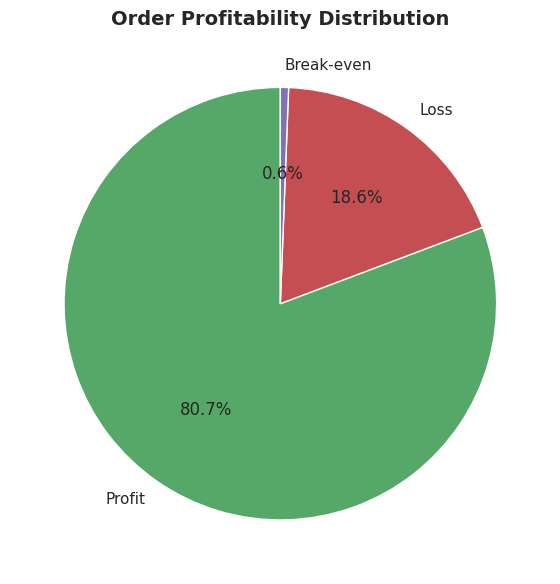

In [ ]:

# Calculate the percentage distribution of profitability categories
profit_counts = df["Profitability"].value_counts(normalize=True) * 100

# Create a pie chart to visualize profitability distribution
plt.figure()
plt.pie(
    profit_counts,
    labels=profit_counts.index,
    autopct="%1.1f%%",
    colors=[SUCCESS, DANGER, NEUTRAL],
    startangle=90
)

# Add chart title and adjust layout
plt.title("Order Profitability Distribution")
plt.tight_layout()
plt.show()

# 6. Calculate Business KPIs

In [ ]:


# Format numerical values into readable currency units (K and M)
def format_money(value):
    if abs(value) >= 1_000_000:
        return f"${value / 1_000_000:.2f}M"
    elif abs(value) >= 1_000:
        return f"${value / 1_000:.2f}K"
    return f"${value:.2f}"


# Calculate delivery performance metrics
total_orders = len(df)
late_orders = df["Is Delayed"].sum()
late_pct = late_orders / total_orders * 100
on_time_pct = 100 - late_pct
p90_delay = df.loc[df["Is Delayed"], "Delay"].quantile(0.90)

# Calculate profitability metrics
total_profit = df.loc[df["Order Item Profit Ratio"] > 0, "Order Item Profit Ratio"].sum()
total_loss = df.loc[df["Order Item Profit Ratio"] < 0, "Order Item Profit Ratio"].sum()
profit_at_risk = df.loc[df["Is Delayed"] & (df["Order Item Profit Ratio"] < 0), "Order Item Profit Ratio"].sum()
avg_profit = df["Order Item Profit Ratio"].mean()

# Store all calculated KPIs in a dictionary
kpis = {
    "Total Orders": total_orders,
    "Late Deliveries": late_orders,
    "Late Delivery %": f"{late_pct:.2f}%",
    "On-Time Delivery %": f"{on_time_pct:.2f}%",
    "Total Profit": format_money(total_profit),
    "Total Loss": format_money(total_loss),
    "Profit at Risk from Delays": format_money(profit_at_risk),
    "90th Percentile Delay": f"{p90_delay:.1f} days",
    "Average Order Profit": format_money(avg_profit)
}

# Display all business KPIs
print("\nBusiness KPIs")
for key, value in kpis.items():
    print(f"{key}: {value}")


Business KPIs
Total Orders: 27472
Late Deliveries: 15534
Late Delivery %: 56.54%
On-Time Delivery %: 43.46%
Total Profit: $6.52K
Total Loss: $-3.16K
Profit at Risk from Delays: $-1.81K
90th Percentile Delay: 3.0 days
Average Order Profit: $0.12


# 7. Delay and Profit Analysis

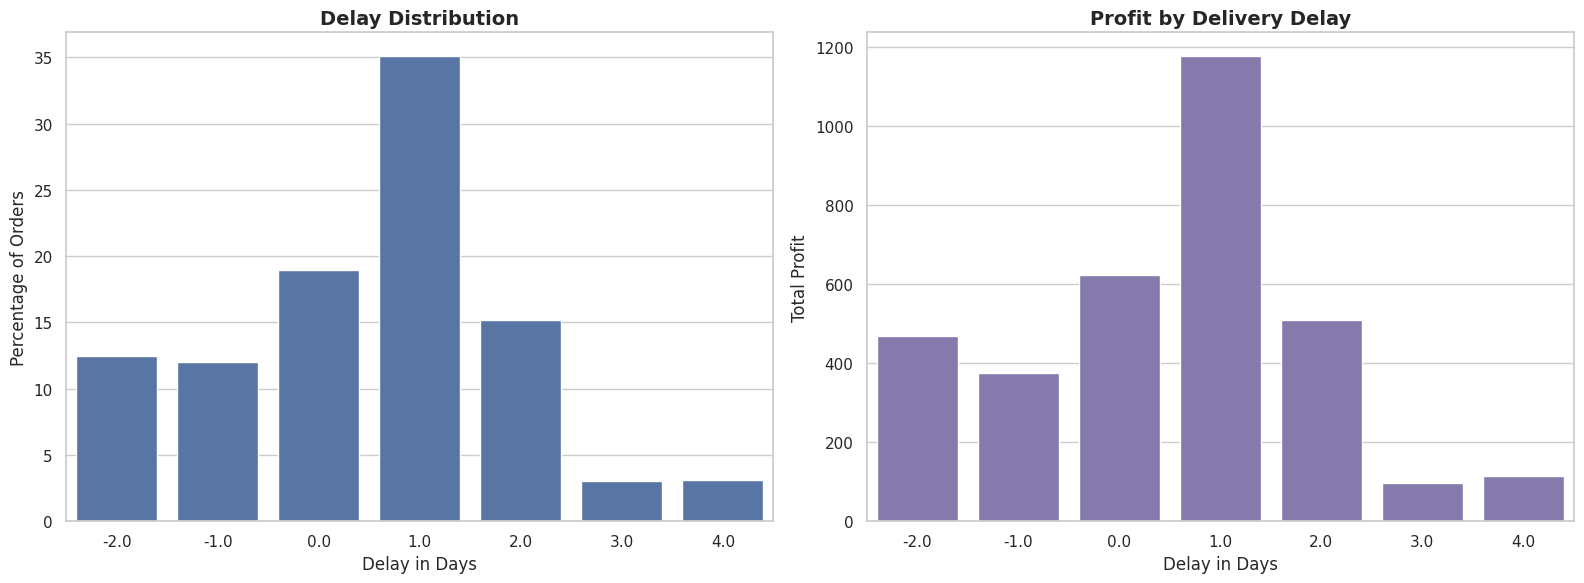

In [ ]:

# Calculate order count and profit metrics for each delay category
profit_by_delay = df.groupby("Delay").agg(
    Orders=("Order Item Profit Ratio", "count"),
    Total_Profit=("Order Item Profit Ratio", "sum"),
    Mean_Profit=("Order Item Profit Ratio", "mean")
).reset_index()

# Calculate the percentage distribution of delivery delays
delay_dist = df["Delay"].value_counts(normalize=True).reset_index()
delay_dist.columns = ["Delay", "Proportion"]
delay_dist["Percentage"] = delay_dist["Proportion"] * 100

# Create two side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Visualize the distribution of delivery delays
sns.barplot(data=delay_dist, x="Delay", y="Percentage", ax=axes[0], color=PRIMARY)
axes[0].set_title("Delay Distribution")
axes[0].set_xlabel("Delay in Days")
axes[0].set_ylabel("Percentage of Orders")

# Visualize total profit across different delay categories
sns.barplot(data=profit_by_delay, x="Delay", y="Total_Profit", ax=axes[1], color=NEUTRAL)
axes[1].set_title("Profit by Delivery Delay")
axes[1].set_xlabel("Delay in Days")
axes[1].set_ylabel("Total Profit")

# Adjust layout and display the charts
plt.tight_layout()
plt.show()

# 8. Bottleneck Detection

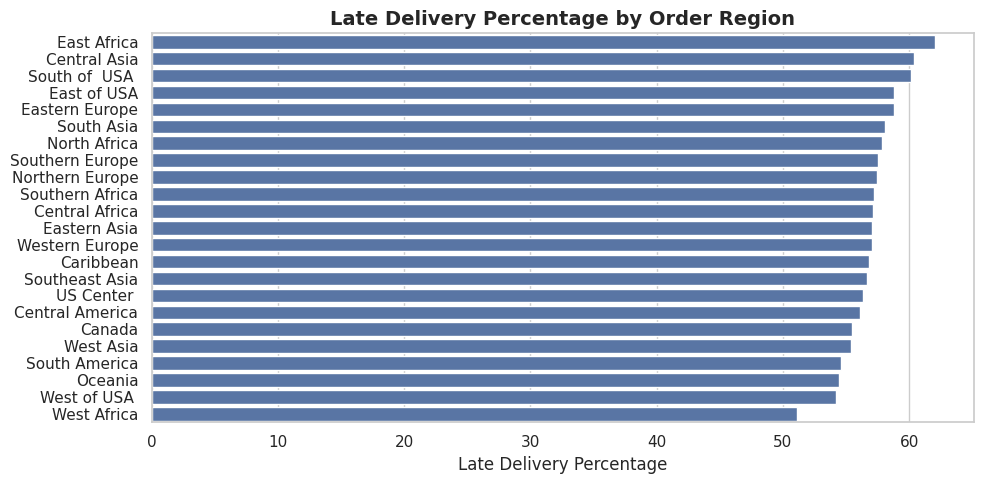

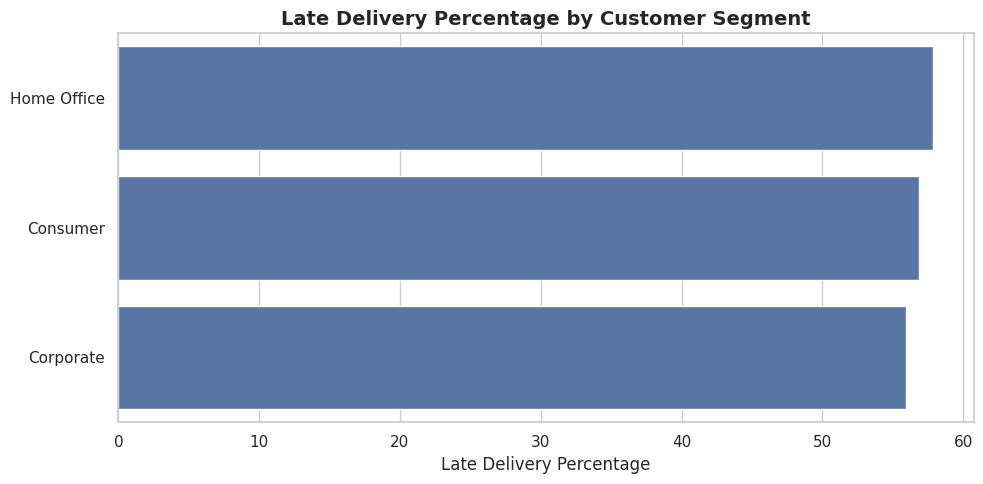

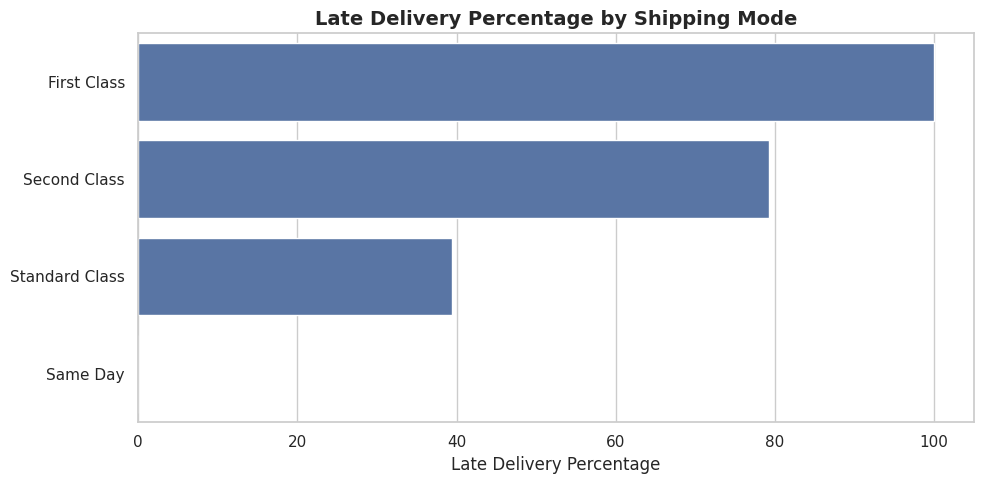

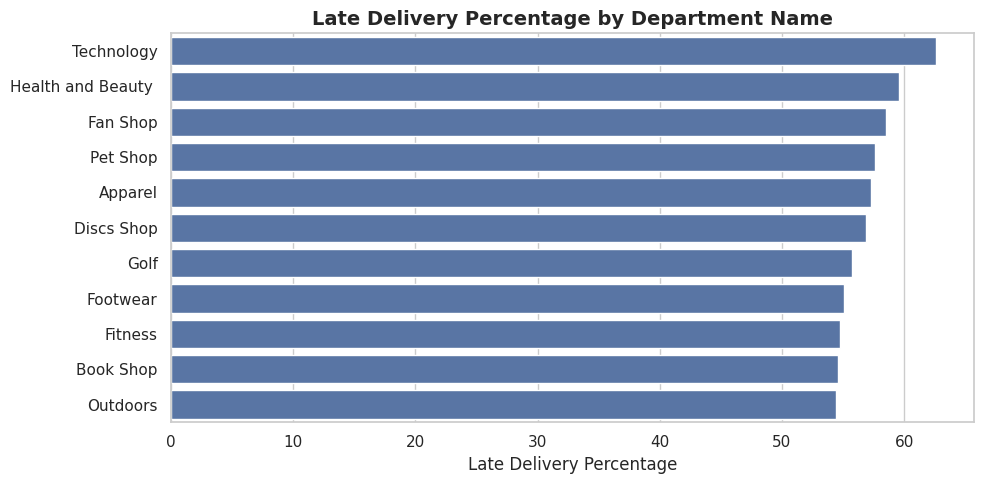

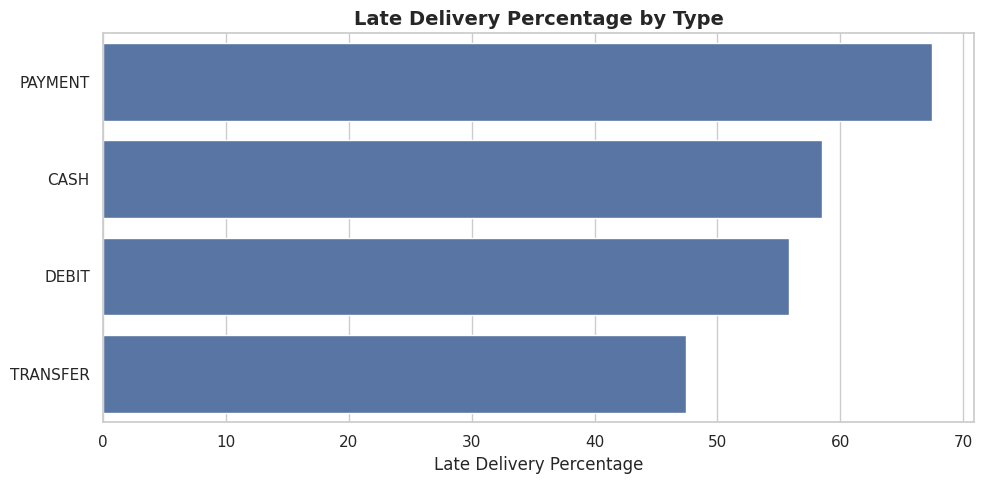

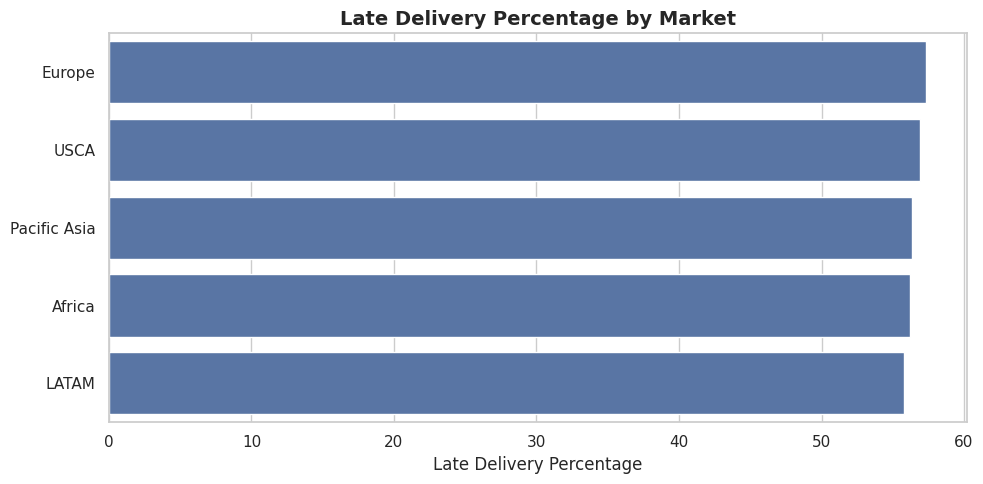

In [ ]:

# Calculate late delivery percentage for each category
def delay_percentage_by_category(data, category):
    result = data.groupby(category).agg(
        Total_Orders=("Is Delayed", "count"),
        Late_Orders=("Is Delayed", "sum")
    ).reset_index()

    result["Delay Percentage"] = result["Late_Orders"] / result["Total_Orders"] * 100
    return result.sort_values("Delay Percentage", ascending=False)


# Define categories for identifying delivery bottlenecks
bottleneck_categories = [
    "Order Region", "Customer Segment", "Shipping Mode",
    "Department Name", "Type", "Market"
]

# Keep only categories available in the dataset
bottleneck_categories = [c for c in bottleneck_categories if c in df.columns]

# Generate a chart for each category
for category in bottleneck_categories:
    cat_df = delay_percentage_by_category(df, category)

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=cat_df,
        x="Delay Percentage",
        y=category,
        color=PRIMARY
    )

    plt.title(f"Late Delivery Percentage by {category}")
    plt.xlabel("Late Delivery Percentage")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

# 9. Root-Cause Analysis


Top delay drivers in Central Africa:
           Factor         Factor Level  Delay Percentage  Average_Delay
0   Shipping Mode          First Class        100.000000       1.000000
24   Order Status      SUSPECTED_FRAUD        100.000000       1.500000
39  Category Name     Tennis & Racquet        100.000000       2.000000
33  Category Name       Girls' Apparel        100.000000       1.333333
26  Category Name  Baseball & Softball        100.000000       1.000000
34  Category Name           Golf Balls        100.000000       2.500000
36  Category Name             Lacrosse        100.000000       1.000000
40  Category Name             Trade-In        100.000000       2.000000
38  Category Name        Shop By Sport         77.419355       0.967742
22   Order Status      PENDING_PAYMENT         76.923077       0.923077


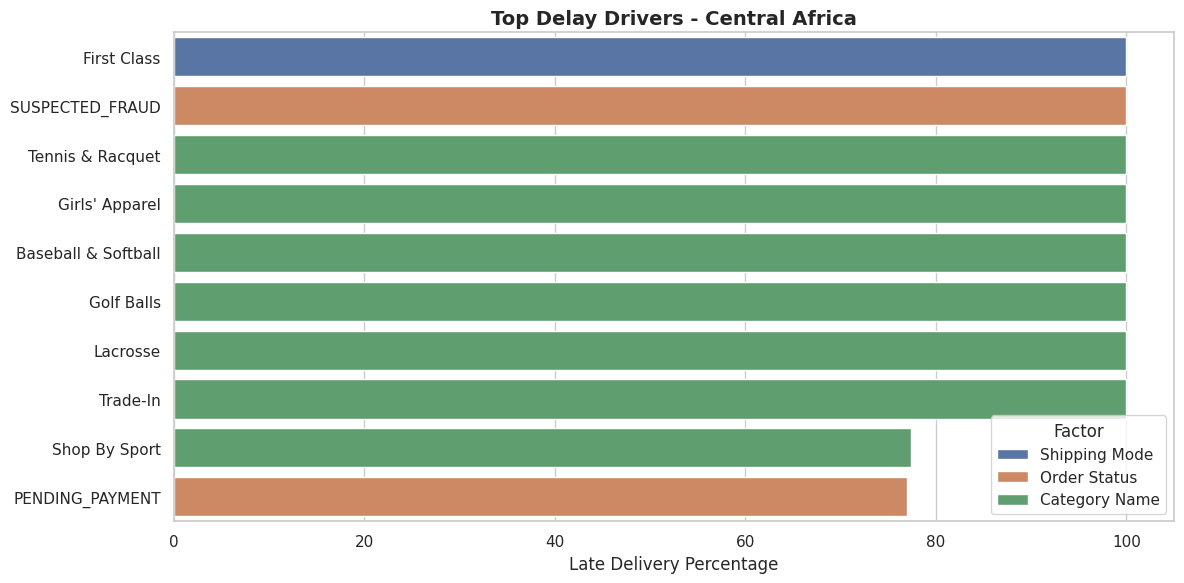

In [ ]:

# Identify the top factors contributing to delivery delays in a region
def top_delay_drivers(data, region, top_n=10):
    region_df = data[data["Order Region"] == region]

    # Define factors to analyze for delivery delays
    driver_columns = [
        "Shipping Mode", "Customer Segment", "Department Name",
        "Type", "Order Status", "Category Name"
    ]
    driver_columns = [c for c in driver_columns if c in region_df.columns]

    all_factors = []

    # Calculate delivery metrics for each factor
    for factor in driver_columns:
        temp = region_df.groupby(factor).agg(
            Total_Orders=("Is Delayed", "count"),
            Late_Orders=("Is Delayed", "sum"),
            Average_Delay=("Delay", "mean")
        ).reset_index()

        # Calculate late delivery percentage
        temp["Delay Percentage"] = temp["Late_Orders"] / temp["Total_Orders"] * 100
        temp["Factor"] = factor
        temp = temp.rename(columns={factor: "Factor Level"})
        all_factors.append(temp)

    # Combine all factors and return the top delay drivers
    final_df = pd.concat(all_factors, ignore_index=True)
    return final_df.sort_values("Delay Percentage", ascending=False).head(top_n)


# Select the region for root-cause analysis
region_to_analyze = "Central Africa"

# Display and visualize the top delay drivers for the selected region
if region_to_analyze in df["Order Region"].unique():
    drivers = top_delay_drivers(df, region_to_analyze)

    print(f"\nTop delay drivers in {region_to_analyze}:")
    print(drivers[["Factor", "Factor Level", "Delay Percentage", "Average_Delay"]])

    # Visualize the top factors contributing to delivery delays
    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=drivers,
        x="Delay Percentage",
        y="Factor Level",
        hue="Factor",
        dodge=False
    )

    plt.title(f"Top Delay Drivers - {region_to_analyze}")
    plt.xlabel("Late Delivery Percentage")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

# 11. Time-Based Analysis

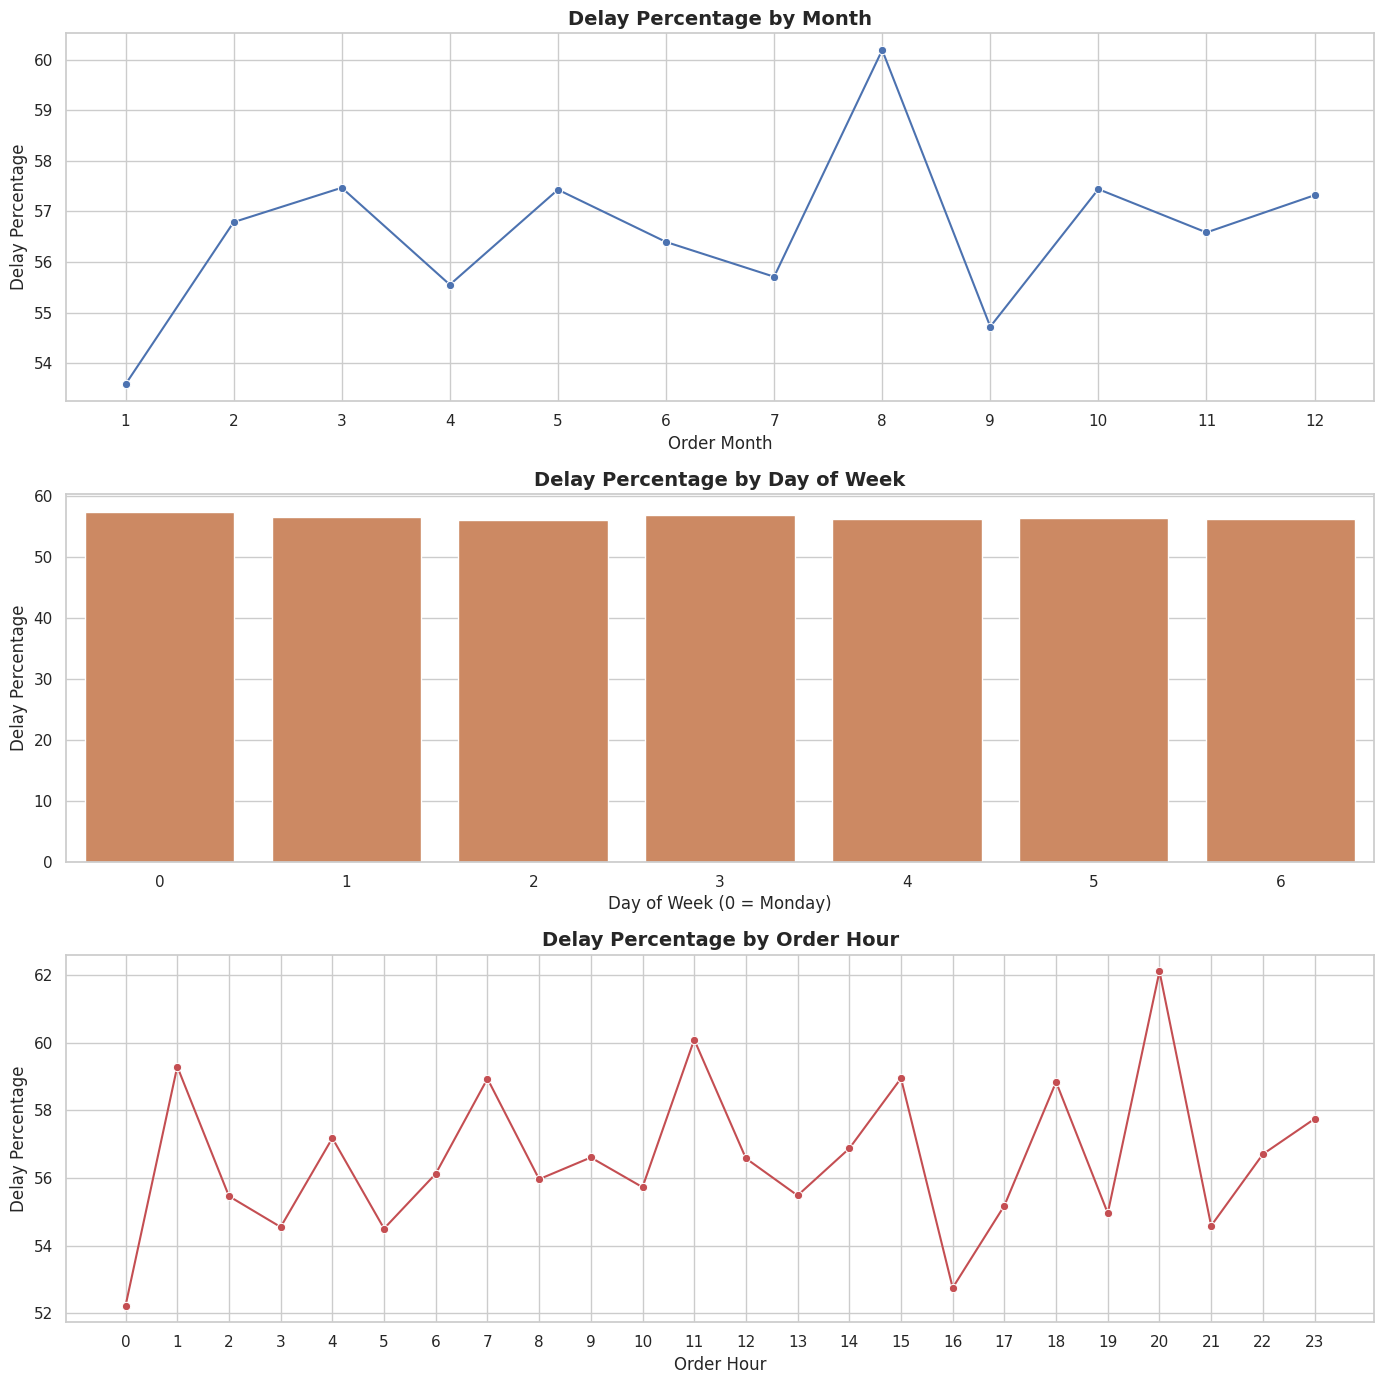

In [ ]:

# Calculate delay percentage by month
month_delay = df.groupby("Order Month")["Is Delayed"].mean().reset_index()
month_delay["Delay Percentage"] = month_delay["Is Delayed"] * 100

# Calculate delay percentage by day of the week
day_delay = df.groupby("Order Day")["Is Delayed"].mean().reset_index()
day_delay["Delay Percentage"] = day_delay["Is Delayed"] * 100

# Calculate delay percentage by order hour
hour_delay = df.groupby("Order Hour")["Is Delayed"].mean().reset_index()
hour_delay["Delay Percentage"] = hour_delay["Is Delayed"] * 100

# Create three charts for time-based delay analysis
fig, axes = plt.subplots(3, 1, figsize=(14, 14))

# Visualize delays by month
sns.lineplot(data=month_delay, x="Order Month", y="Delay Percentage", marker="o", ax=axes[0], color=PRIMARY)
axes[0].set_title("Delay Percentage by Month")
axes[0].set_xticks(range(1, 13))

# Visualize delays by day of the week
sns.barplot(data=day_delay, x="Order Day", y="Delay Percentage", ax=axes[1], color=SECONDARY)
axes[1].set_title("Delay Percentage by Day of Week")
axes[1].set_xlabel("Day of Week (0 = Monday)")

# Visualize delays by order hour
sns.lineplot(data=hour_delay, x="Order Hour", y="Delay Percentage", marker="o", ax=axes[2], color=DANGER)
axes[2].set_title("Delay Percentage by Order Hour")
axes[2].set_xticks(range(0, 24))

# Adjust spacing and display all charts
plt.tight_layout()
plt.show()

# 12. Machine Learning: Predict Late Delivery


Model Performance
Accuracy: 0.7328480436760691
Precision: 0.9100096246390761
Recall: 0.5961538461538461
F1 Score: 0.7203809523809523
ROC AUC: 0.8132060067128484

Classification Report
              precision    recall  f1-score   support

           0       0.63      0.92      0.74      2323
           1       0.91      0.60      0.72      3172

    accuracy                           0.73      5495
   macro avg       0.77      0.76      0.73      5495
weighted avg       0.79      0.73      0.73      5495



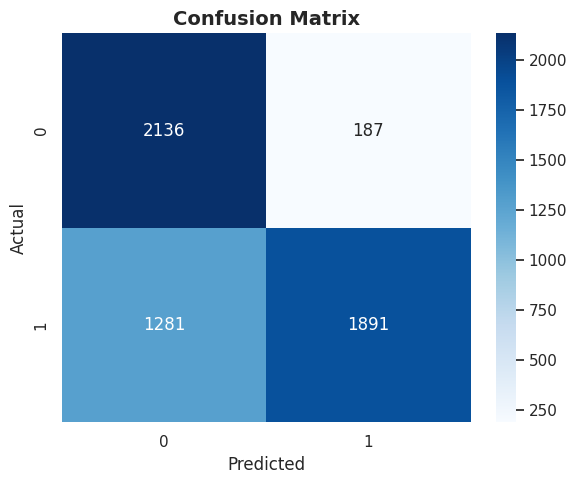

In [ ]:

# Create a copy of the dataset for model development
model_df = df.copy()

# Define the target variable
target = "Late_delivery_risk"

# Select relevant features for predicting late deliveries
features = [
    "Days for shipment (scheduled)", "Category Name", "Customer Segment",
    "Department Name", "Order Region", "Shipping Mode",
    "Order Month", "Order Hour", "Order Day"
]

# Keep only features available in the dataset
features = [c for c in features if c in model_df.columns]

# Remove rows containing missing values
model_df = model_df[features + [target]].dropna()

# Apply frequency encoding to categorical variables
for col in model_df.select_dtypes(include="object").columns:
    freq = model_df[col].value_counts(normalize=True)
    model_df[col + "_freq"] = model_df[col].map(freq)
    model_df = model_df.drop(columns=col)

# Separate independent features and target variable
X = model_df.drop(columns=[target])
y = model_df[target]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize features using training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize the Random Forest classification model
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model using the training dataset
model.fit(X_train_scaled, y_train)

# Generate predictions and prediction probabilities
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

# Evaluate model performance using classification metrics
print("\nModel Performance")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_proba))

# Display the detailed classification report
print("\nClassification Report")
print(classification_report(y_test, y_pred))

# Visualize model predictions using a confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# 13. Feature Importance

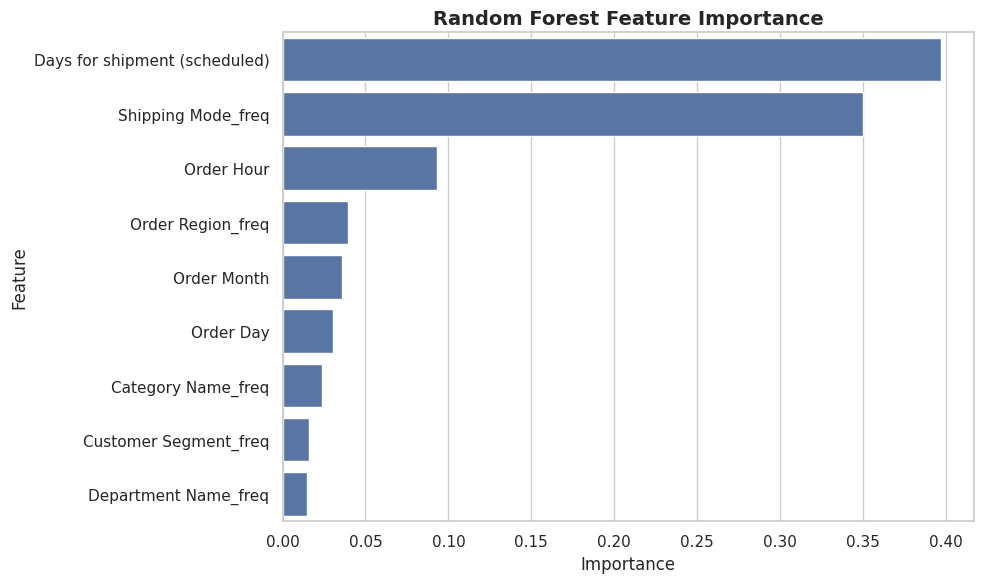

In [ ]:

# Extract and rank feature importance scores from the model
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

# Visualize the importance of each feature
plt.figure(figsize=(10, 6))
sns.barplot(data=importance, x="Importance", y="Feature", color=PRIMARY)

plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()